In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import shap
import os
import random

from sklearn.model_selection import cross_val_score
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.svm import SVR
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import f1_score

import optuna
from xgboost import XGBClassifier


SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)

print("Seed fixée à", SEED)

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Seed fixée à 42


In [2]:
df = pd.read_csv("Drinking_water.csv", sep=",")

In [3]:
print("water shape:", df.shape)
print("Columns:", list(df.columns))

water shape: (3276, 13)
Columns: ['Unnamed: 0', 'ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity', 'Potability', 'Carcinogenics', 'medical_waste']


In [4]:
df

,Unnamed: 0,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability,Carcinogenics,medical_waste
0,0,NaN,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0,NaN,NaN
1,1,3.716080,129.422921,18630.057858,6.635246,NaN,592.885359,15.180013,56.329076,4.500656,0,NaN,NaN
2,2,8.099124,224.236259,19909.541732,9.275884,NaN,418.606213,16.868637,66.420093,3.055934,0,NaN,NaN
3,3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0,NaN,NaN
4,4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3271,3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1,NaN,NaN
3272,3272,7.808856,193.553212,17329.802160,8.061362,NaN,392.449580,19.903225,NaN,2.798243,1,NaN,NaN
3273,3273,9.419510,175.762646,33155.578218,7.350233,NaN,432.044783,11.039070,69.845400,3.298875,1,NaN,NaN
3274,3274,5.126763,230.603758,11983.869376,6.303357,NaN,402.883113,11.168946,77.488213,4.708658,1,NaN,NaN


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       3276 non-null   int64  
 1   ph               2785 non-null   float64
 2   Hardness         3276 non-null   float64
 3   Solids           3276 non-null   float64
 4   Chloramines      3276 non-null   float64
 5   Sulfate          2495 non-null   float64
 6   Conductivity     3276 non-null   float64
 7   Organic_carbon   3276 non-null   float64
 8   Trihalomethanes  3114 non-null   float64
 9   Turbidity        3276 non-null   float64
 10  Potability       3276 non-null   int64  
 11  Carcinogenics    0 non-null      float64
 12  medical_waste    0 non-null      float64
dtypes: float64(11), int64(2)
memory usage: 332.8 KB


In [6]:
df.describe()

,Unnamed: 0,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability,Carcinogenics,medical_waste
count,3276.000000,2785.000000,3276.000000,3276.000000,3276.000000,2495.000000,3276.000000,3276.000000,3114.000000,3276.000000,3276.000000,0.0,0.0
mean,1637.500000,7.080795,196.369496,22014.092526,7.122277,333.775777,426.205111,14.284970,66.396293,3.966786,0.390110,NaN,NaN
std,945.844067,1.594320,32.879761,8768.570828,1.583085,41.416840,80.824064,3.308162,16.175008,0.780382,0.487849,NaN,NaN
min,0.000000,0.000000,47.432000,320.942611,0.352000,129.000000,181.483754,2.200000,0.738000,1.450000,0.000000,NaN,NaN
25%,818.750000,6.093092,176.850538,15666.690297,6.127421,307.699498,365.734414,12.065801,55.844536,3.439711,0.000000,NaN,NaN
50%,1637.500000,7.036752,196.967627,20927.833607,7.130299,333.073546,421.884968,14.218338,66.622485,3.955028,0.000000,NaN,NaN
75%,2456.250000,8.062066,216.667456,27332.762127,8.114887,359.950170,481.792304,16.557652,77.337473,4.500320,1.000000,NaN,NaN
max,3275.000000,14.000000,323.124000,61227.196008,13.127000,481.030642,753.342620,28.300000,124.000000,6.739000,1.000000,NaN,NaN


In [7]:
df.isna().sum()

Unnamed: 0            0
ph                  491
Hardness              0
Solids                0
Chloramines           0
Sulfate             781
Conductivity          0
Organic_carbon        0
Trihalomethanes     162
Turbidity             0
Potability            0
Carcinogenics      3276
medical_waste      3276
dtype: int64

In [8]:
df = df.drop(columns=['Carcinogenics', 'medical_waste'])


In [9]:
df.isna().sum()

Unnamed: 0           0
ph                 491
Hardness             0
Solids               0
Chloramines          0
Sulfate            781
Conductivity         0
Organic_carbon       0
Trihalomethanes    162
Turbidity            0
Potability           0
dtype: int64

In [10]:
#remplir les cases vides par la moyenne du column car les lignes des cases vides couvrent 40% du dataset

df['ph'] = df['ph'].fillna(df['ph'].mean())
df['Sulfate'] = df['Sulfate'].fillna(df['Sulfate'].mean())
df['Trihalomethanes'] = df['Trihalomethanes'].fillna(df['Trihalomethanes'].mean())

In [11]:
df.isna().sum()

Unnamed: 0         0
ph                 0
Hardness           0
Solids             0
Chloramines        0
Sulfate            0
Conductivity       0
Organic_carbon     0
Trihalomethanes    0
Turbidity          0
Potability         0
dtype: int64

In [12]:
df.isna().sum().sum()

np.int64(0)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3276 entries, 0 to 3275
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       3276 non-null   int64  
 1   ph               3276 non-null   float64
 2   Hardness         3276 non-null   float64
 3   Solids           3276 non-null   float64
 4   Chloramines      3276 non-null   float64
 5   Sulfate          3276 non-null   float64
 6   Conductivity     3276 non-null   float64
 7   Organic_carbon   3276 non-null   float64
 8   Trihalomethanes  3276 non-null   float64
 9   Turbidity        3276 non-null   float64
 10  Potability       3276 non-null   int64  
dtypes: float64(9), int64(2)
memory usage: 281.7 KB


In [14]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.shape

(3276, 11)

In [16]:
df

,Unnamed: 0,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...,...
3271,3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,3272,7.808856,193.553212,17329.802160,8.061362,333.775777,392.449580,19.903225,66.396293,2.798243,1
3273,3273,9.419510,175.762646,33155.578218,7.350233,333.775777,432.044783,11.039070,69.845400,3.298875,1
3274,3274,5.126763,230.603758,11983.869376,6.303357,333.775777,402.883113,11.168946,77.488213,4.708658,1


In [17]:
print(df["Potability"].value_counts().sort_index())
print()
print((df["Potability"].value_counts(normalize=True).sort_index() * 100).round(2))

Potability
0    1998
1    1278
Name: count, dtype: int64

Potability
0    60.99
1    39.01
Name: proportion, dtype: float64


In [18]:
print("Quality Points:",df['Potability'].unique())

Quality Points: [0 1]


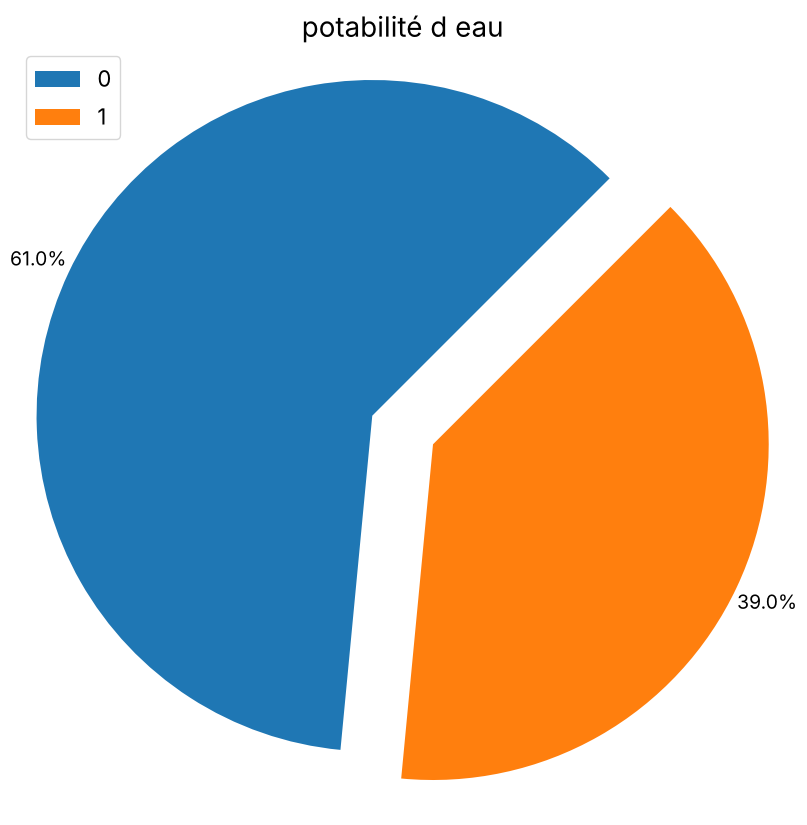

In [19]:
potability = df["Potability"].value_counts().sort_index(ascending=True)

explode_list = [0.1, 0.1]

ax = potability.plot(kind='pie',
                     figsize=(10,10),
                     autopct='%1.1f%%',
                     startangle=45,
                     labels=None,
                     pctdistance=1.1,
                     explode=explode_list,
                     textprops={'fontsize': 14})

ax.patch.set_facecolor('white')
plt.title('potabilité d eau', size = 20)
ax.set(ylabel=None)
plt.axis('equal')
plt.legend(labels=potability.index, loc="upper left", fontsize=16)

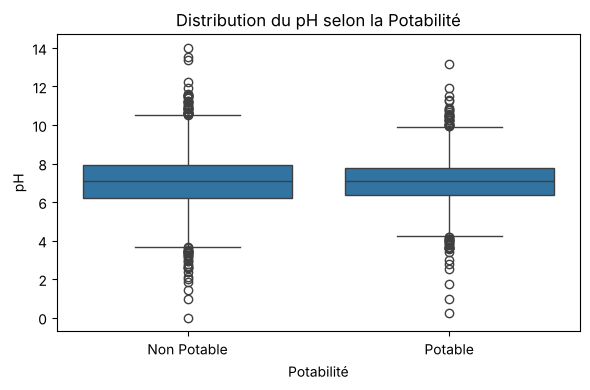

In [20]:
plt.figure(figsize=(6, 4))

# Distribution du pH selon la potabilité
ax = sns.boxplot(data=df, x="Potability", y="ph")

ax.set_xticks([0, 1])
# Adapter les étiquettes (0 = Non Potable, 1 = Potable)
ax.set_xticklabels(["Non Potable", "Potable"])

plt.title("Distribution du pH selon la Potabilité")
plt.xlabel("Potabilité")
plt.ylabel("pH")
plt.tight_layout()
plt.show()

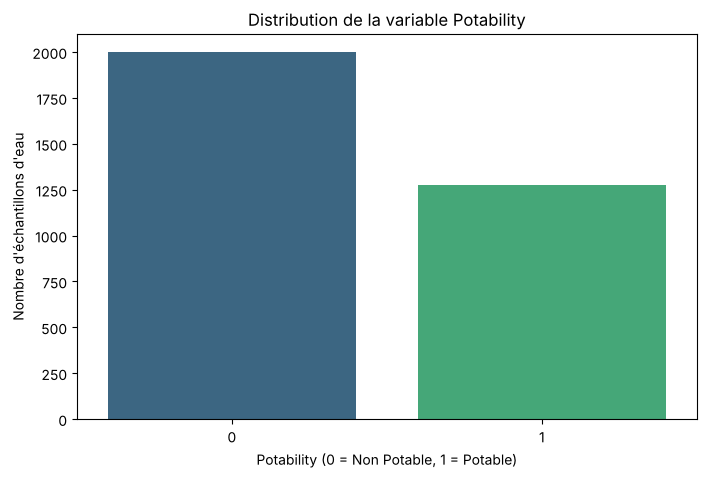

In [21]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Potability", hue="Potability", palette="viridis", legend=False)

plt.title("Distribution de la variable Potability")
plt.xlabel("Potability (0 = Non Potable, 1 = Potable)")
plt.ylabel("Nombre d'échantillons d'eau")

plt.show()

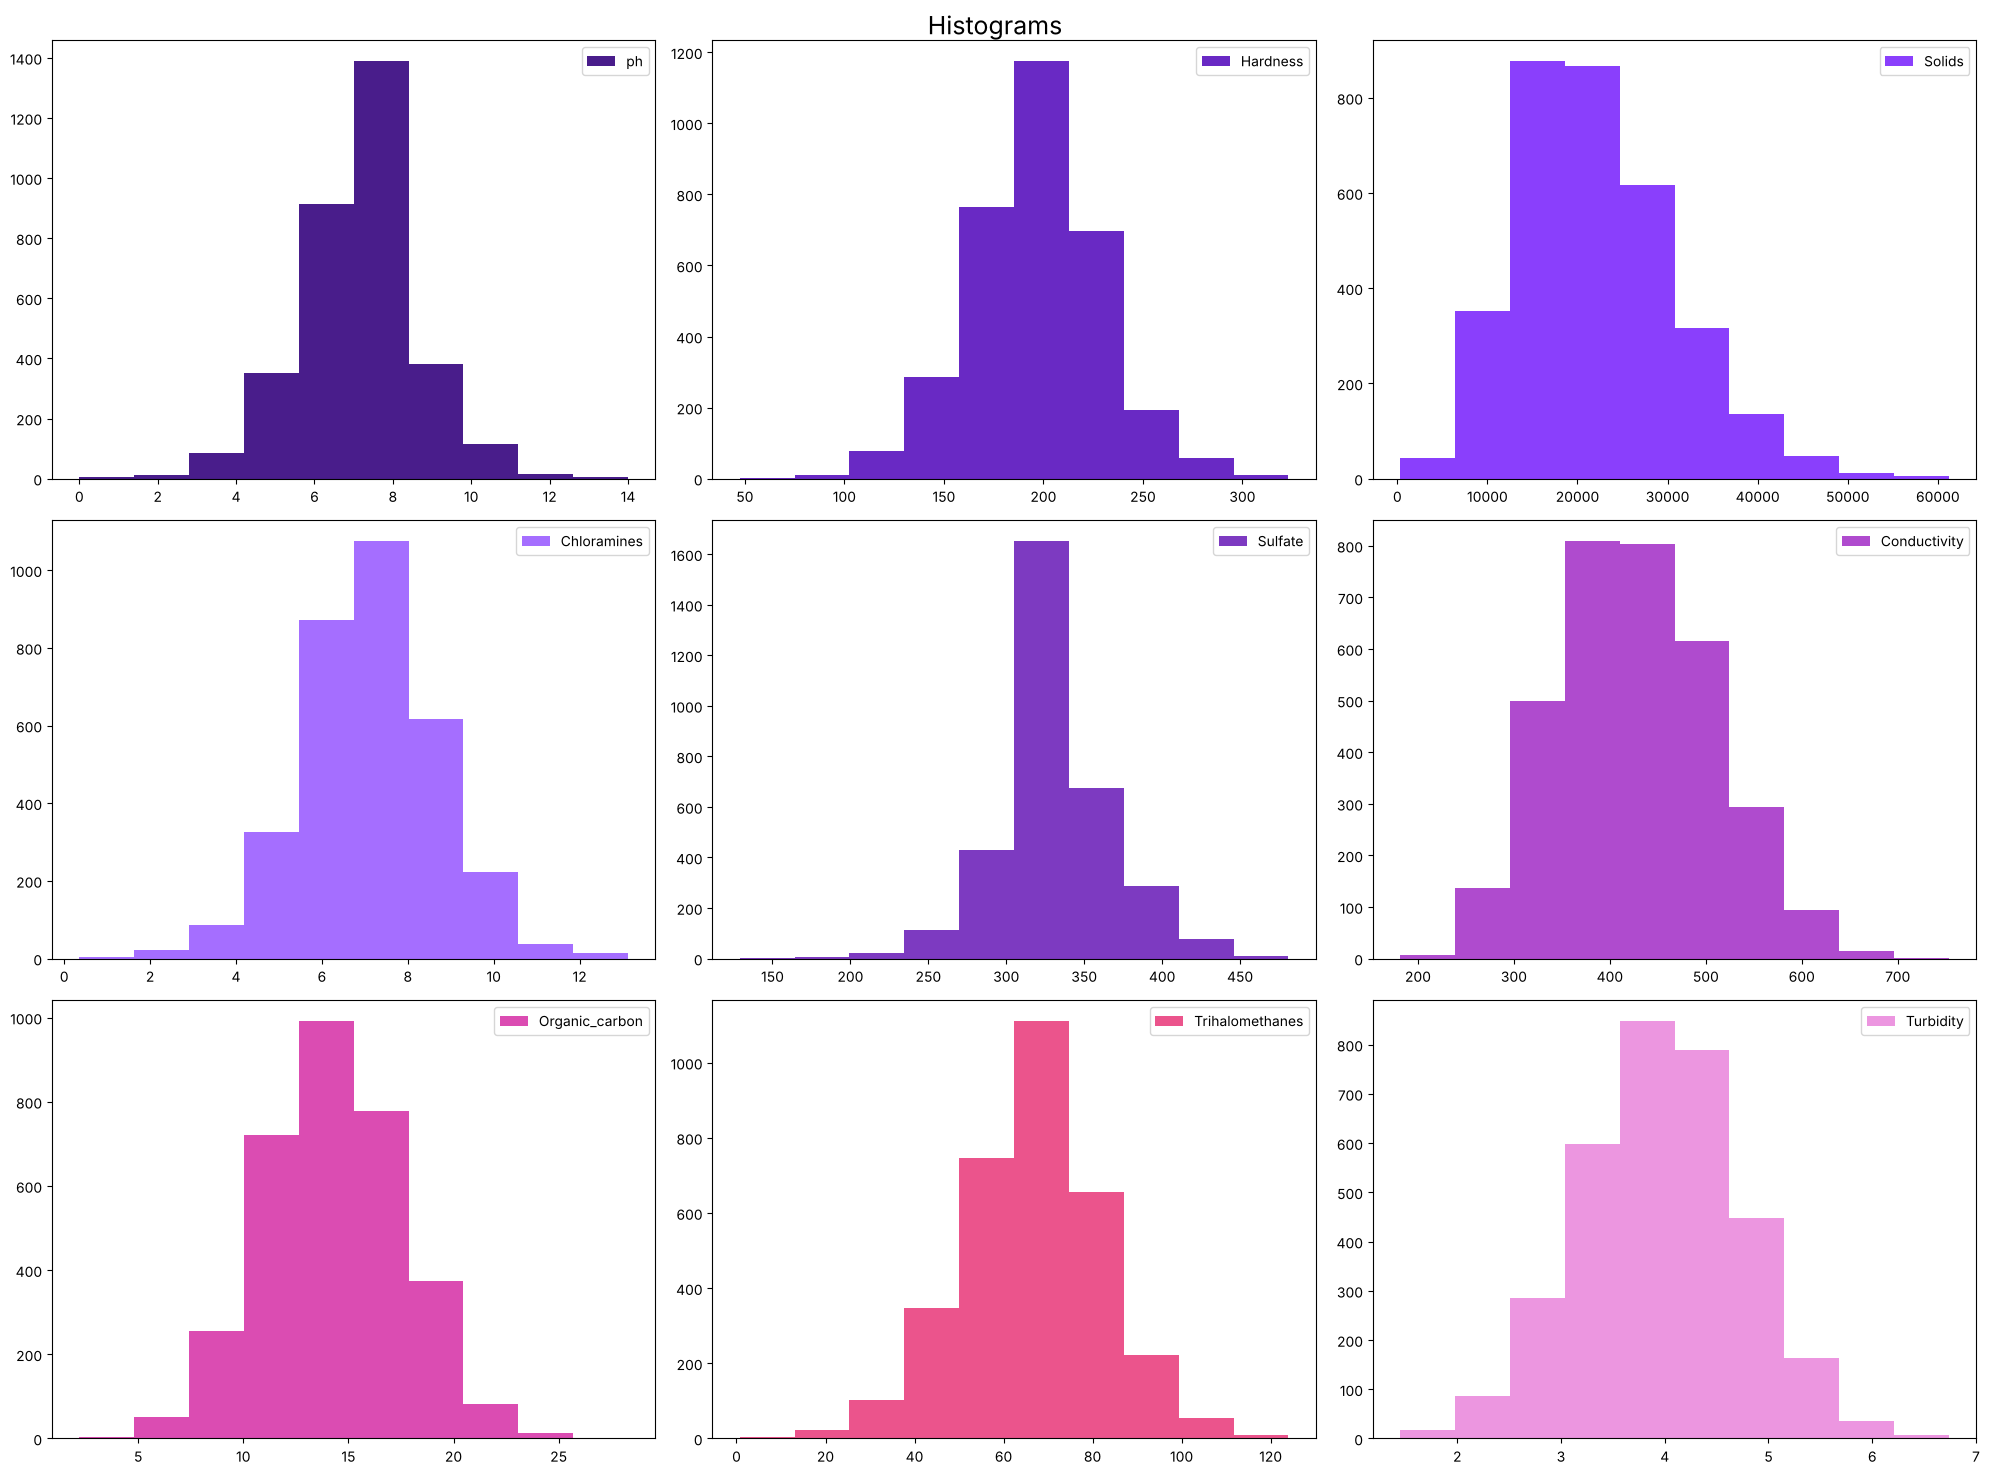

In [22]:
import math
import matplotlib.pyplot as plt

colonnes = ['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 
            'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']

n_cols = 3
n_plots = len(colonnes)
n_rows = math.ceil(n_plots / n_cols)

fig, axes = plt.subplots(nrows=n_rows, ncols=n_cols, figsize=(20, 5 * n_rows))
axes = axes.flatten()

colors = ['#491D8B', '#6929C4', '#8A3FFC', '#A56EFF',
          '#7D3AC1', '#AF4BCE', '#DB4CB2', '#EB548C',
          '#EC96E0', '#A2128E', '#E8D9F3', '#641811',
          '#B22222', '#2E8B57', '#FF8C00']

for index, column in enumerate(colonnes):
    ax = axes[index]
    ax.hist(df[column].dropna(), color=colors[index % len(colors)], label=column) # dropna() évite les erreurs si des vides restent
    ax.legend(loc="best")

for j in range(len(colonnes), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Histograms", size=18)
plt.tight_layout()
plt.show()

In [23]:
print(df["Potability"].value_counts().sort_index())

Potability
0    1998
1    1278
Name: count, dtype: int64


In [24]:
fig = px.ecdf(df, x = "ph", log_x = True, log_y = True, color = "Potability")
fig.show()

In [25]:
fig = px.ecdf(df, x = "Sulfate", log_x = True, log_y = True, color = "Potability")
fig.show()

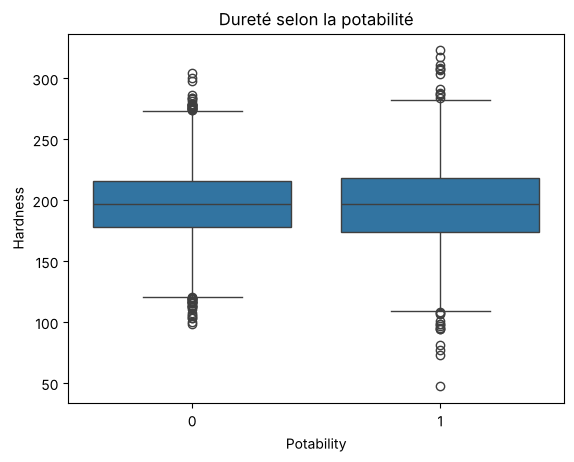

In [26]:
sns.boxplot(data=df, x="Potability", y="Hardness")
plt.title("Dureté selon la potabilité")
plt.show()

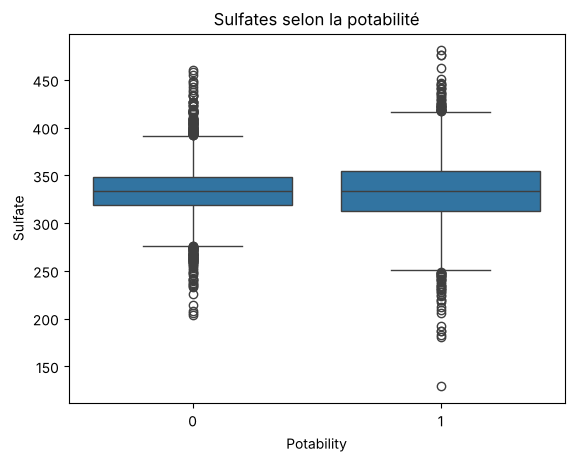

In [27]:
sns.boxplot(data=df, x="Potability", y="Sulfate")
plt.title("Sulfates selon la potabilité")
plt.show()

In [28]:
print(df["Potability"].value_counts())
print()
print((df["Potability"].value_counts(normalize=True) * 100).round(2))

Potability
0    1998
1    1278
Name: count, dtype: int64

Potability
0    60.99
1    39.01
Name: proportion, dtype: float64


In [29]:
df


,Unnamed: 0,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...,...
3271,3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,3272,7.808856,193.553212,17329.802160,8.061362,333.775777,392.449580,19.903225,66.396293,2.798243,1
3273,3273,9.419510,175.762646,33155.578218,7.350233,333.775777,432.044783,11.039070,69.845400,3.298875,1
3274,3274,5.126763,230.603758,11983.869376,6.303357,333.775777,402.883113,11.168946,77.488213,4.708658,1


In [30]:
df=df.drop(columns=['Unnamed: 0'])

In [31]:
df

,ph,Hardness,Solids,Chloramines,Sulfate,Conductivity,Organic_carbon,Trihalomethanes,Turbidity,Potability
0,7.080795,204.890455,20791.318981,7.300212,368.516441,564.308654,10.379783,86.990970,2.963135,0
1,3.716080,129.422921,18630.057858,6.635246,333.775777,592.885359,15.180013,56.329076,4.500656,0
2,8.099124,224.236259,19909.541732,9.275884,333.775777,418.606213,16.868637,66.420093,3.055934,0
3,8.316766,214.373394,22018.417441,8.059332,356.886136,363.266516,18.436524,100.341674,4.628771,0
4,9.092223,181.101509,17978.986339,6.546600,310.135738,398.410813,11.558279,31.997993,4.075075,0
...,...,...,...,...,...,...,...,...,...,...
3271,4.668102,193.681735,47580.991603,7.166639,359.948574,526.424171,13.894419,66.687695,4.435821,1
3272,7.808856,193.553212,17329.802160,8.061362,333.775777,392.449580,19.903225,66.396293,2.798243,1
3273,9.419510,175.762646,33155.578218,7.350233,333.775777,432.044783,11.039070,69.845400,3.298875,1
3274,5.126763,230.603758,11983.869376,6.303357,333.775777,402.883113,11.168946,77.488213,4.708658,1


In [32]:
X = df.drop(columns=["Potability"])
y = df["Potability"]

print("Shape de X :", X.shape)
print("Shape de y :", y.shape)
print(X.columns.tolist())

Shape de X : (3276, 9)
Shape de y : (3276,)
['ph', 'Hardness', 'Solids', 'Chloramines', 'Sulfate', 'Conductivity', 'Organic_carbon', 'Trihalomethanes', 'Turbidity']


In [33]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test  :", y_test.shape)

X_train : (2620, 9)
X_test  : (656, 9)
y_train : (2620,)
y_test  : (656,)


In [34]:
# 5) Vérification rapide du déséquilibre dans train et test

print("Distribution y_train :")
print(y_train.value_counts())
print((y_train.value_counts(normalize=True) * 100).round(2))

print()
print("Distribution y_test :")
print(y_test.value_counts())
print((y_test.value_counts(normalize=True) * 100).round(2))

Distribution y_train :
Potability
0    1598
1    1022
Name: count, dtype: int64
Potability
0    60.99
1    39.01
Name: proportion, dtype: float64

Distribution y_test :
Potability
0    400
1    256
Name: count, dtype: int64
Potability
0    60.98
1    39.02
Name: proportion, dtype: float64


In [35]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(
    random_state=42,
    max_iter=1000,
    class_weight="balanced"
)

log_model.fit(X_train_scaled, y_train)

y_pred_log = log_model.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_log))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_log))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_log))

Accuracy : 0.5274390243902439

Confusion Matrix :
[[208 192]
 [118 138]]

Classification Report :
              precision    recall  f1-score   support

           0       0.64      0.52      0.57       400
           1       0.42      0.54      0.47       256

    accuracy                           0.53       656
   macro avg       0.53      0.53      0.52       656
weighted avg       0.55      0.53      0.53       656



In [36]:
#  Standardisation

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X_train_scaled :", X_train_scaled.shape)
print("X_test_scaled  :", X_test_scaled.shape)

X_train_scaled : (2620, 9)
X_test_scaled  : (656, 9)


In [37]:
# SMOTE sur le TRAIN seulement

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

print("Après SMOTE :")
print("X_train_smote :", X_train_smote.shape)
print(y_train_smote.value_counts())
print((y_train_smote.value_counts(normalize=True) * 100).round(2))

Après SMOTE :
X_train_smote : (3196, 9)
Potability
0    1598
1    1598
Name: count, dtype: int64
Potability
0    50.0
1    50.0
Name: proportion, dtype: float64


In [38]:
# Logistic Regression avec les données SMOTE

log_model_smote = LogisticRegression(
    random_state=42,
    max_iter=1000
)

log_model_smote.fit(X_train_smote, y_train_smote)

y_pred_log_smote = log_model_smote.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_log_smote))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_log_smote))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_log_smote))

Accuracy : 0.5259146341463414

Confusion Matrix :
[[208 192]
 [119 137]]

Classification Report :
              precision    recall  f1-score   support

           0       0.64      0.52      0.57       400
           1       0.42      0.54      0.47       256

    accuracy                           0.53       656
   macro avg       0.53      0.53      0.52       656
weighted avg       0.55      0.53      0.53       656



In [39]:
log_model_smote = LogisticRegression(random_state=42, max_iter=1000)
log_model_smote.fit(X_train_smote, y_train_smote)

y_pred_log_smote = log_model_smote.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_log_smote))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_log_smote))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_log_smote))


from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Modele": ["LogReg_balanced", "LogReg_SMOTE"],
    "Accuracy": [accuracy_score(y_test, y_pred_log), accuracy_score(y_test, y_pred_log_smote)],
    "Precision_classe_1": [precision_score(y_test, y_pred_log, pos_label=1), precision_score(y_test, y_pred_log_smote, pos_label=1)],
    "Recall_classe_1": [recall_score(y_test, y_pred_log, pos_label=1), recall_score(y_test, y_pred_log_smote, pos_label=1)],
    "F1_classe_1": [f1_score(y_test, y_pred_log, pos_label=1), f1_score(y_test, y_pred_log_smote, pos_label=1)]
})

print(comparison)


Accuracy : 0.5259146341463414

Confusion Matrix :
[[208 192]
 [119 137]]

Classification Report :
              precision    recall  f1-score   support

           0       0.64      0.52      0.57       400
           1       0.42      0.54      0.47       256

    accuracy                           0.53       656
   macro avg       0.53      0.53      0.52       656
weighted avg       0.55      0.53      0.53       656

            Modele  Accuracy  Precision_classe_1  Recall_classe_1  F1_classe_1
0  LogReg_balanced  0.527439            0.418182         0.539062     0.470990
1     LogReg_SMOTE  0.525915            0.416413         0.535156     0.468376


In [40]:
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_rf))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_rf))

Accuracy : 0.649390243902439

Confusion Matrix :
[[318  82]
 [148 108]]

Classification Report :
              precision    recall  f1-score   support

           0       0.68      0.80      0.73       400
           1       0.57      0.42      0.48       256

    accuracy                           0.65       656
   macro avg       0.63      0.61      0.61       656
weighted avg       0.64      0.65      0.64       656



In [41]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison_models = pd.DataFrame({
    "Modele": ["LogReg_balanced", "LogReg_SMOTE", "RandomForest"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_log_smote),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision_classe_1": [
        precision_score(y_test, y_pred_log, pos_label=1),
        precision_score(y_test, y_pred_log_smote, pos_label=1),
        precision_score(y_test, y_pred_rf, pos_label=1)
    ],
    "Recall_classe_1": [
        recall_score(y_test, y_pred_log, pos_label=1),
        recall_score(y_test, y_pred_log_smote, pos_label=1),
        recall_score(y_test, y_pred_rf, pos_label=1)
    ],
    "F1_classe_1": [
        f1_score(y_test, y_pred_log, pos_label=1),
        f1_score(y_test, y_pred_log_smote, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1)
    ]
})

print(comparison_models)

            Modele  Accuracy  Precision_classe_1  Recall_classe_1  F1_classe_1
0  LogReg_balanced  0.527439            0.418182         0.539062     0.470990
1     LogReg_SMOTE  0.525915            0.416413         0.535156     0.468376
2     RandomForest  0.649390            0.568421         0.421875     0.484305


In [42]:
rf_model_smote = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

rf_model_smote.fit(X_train_smote, y_train_smote)

y_pred_rf_smote = rf_model_smote.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_rf_smote))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_rf_smote))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_rf_smote))

Accuracy : 0.6539634146341463

Confusion Matrix :
[[314  86]
 [141 115]]

Classification Report :
              precision    recall  f1-score   support

           0       0.69      0.79      0.73       400
           1       0.57      0.45      0.50       256

    accuracy                           0.65       656
   macro avg       0.63      0.62      0.62       656
weighted avg       0.64      0.65      0.64       656



In [43]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison_models = pd.DataFrame({
    "Modele": ["LogReg_balanced", "LogReg_SMOTE", "RandomForest", "RF_SMOTE"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_log_smote),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_smote)
    ],
    "Precision_classe_1": [
        precision_score(y_test, y_pred_log, pos_label=1),
        precision_score(y_test, y_pred_log_smote, pos_label=1),
        precision_score(y_test, y_pred_rf, pos_label=1),
        precision_score(y_test, y_pred_rf_smote, pos_label=1)
    ],
    "Recall_classe_1": [
        recall_score(y_test, y_pred_log, pos_label=1),
        recall_score(y_test, y_pred_log_smote, pos_label=1),
        recall_score(y_test, y_pred_rf, pos_label=1),
        recall_score(y_test, y_pred_rf_smote, pos_label=1)
    ],
    "F1_classe_1": [
        f1_score(y_test, y_pred_log, pos_label=1),
        f1_score(y_test, y_pred_log_smote, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf_smote, pos_label=1)
    ]
})

print(comparison_models)

            Modele  Accuracy  Precision_classe_1  Recall_classe_1  F1_classe_1
0  LogReg_balanced  0.527439            0.418182         0.539062     0.470990
1     LogReg_SMOTE  0.525915            0.416413         0.535156     0.468376
2     RandomForest  0.649390            0.568421         0.421875     0.484305
3         RF_SMOTE  0.653963            0.572139         0.449219     0.503282


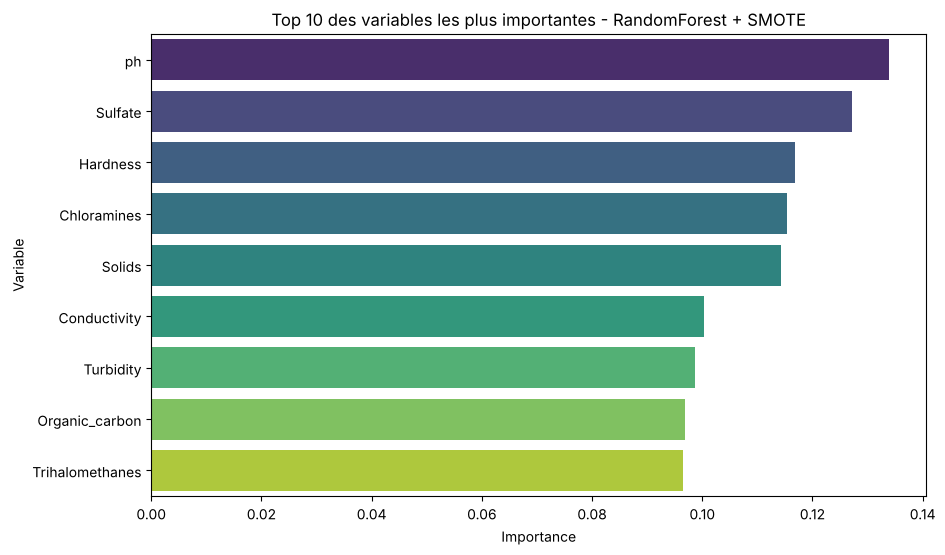

In [44]:
feature_importance = pd.DataFrame({
    "feature": X.columns,
    "importance": rf_model_smote.feature_importances_
}).sort_values(by="importance", ascending=False)


plt.figure(figsize=(10, 6))
sns.barplot(
    data=feature_importance.head(10),
    x="importance",
    y="feature",
    hue="feature",
    palette="viridis",
    legend=False
)
plt.title("Top 10 des variables les plus importantes - RandomForest + SMOTE")
plt.xlabel("Importance")
plt.ylabel("Variable")
plt.show()

In [45]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_smote, y_train_smote)

y_pred_knn = knn_model.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_knn))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_knn))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_knn))

Accuracy : 0.5838414634146342

Confusion Matrix :
[[256 144]
 [129 127]]

Classification Report :
              precision    recall  f1-score   support

           0       0.66      0.64      0.65       400
           1       0.47      0.50      0.48       256

    accuracy                           0.58       656
   macro avg       0.57      0.57      0.57       656
weighted avg       0.59      0.58      0.59       656



In [46]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison_models = pd.DataFrame({
    "Modele": ["LogReg_balanced", "LogReg_SMOTE", "RandomForest", "RF_SMOTE", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_log),
        accuracy_score(y_test, y_pred_log_smote),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_rf_smote),
        accuracy_score(y_test, y_pred_knn)
    ],
    "Precision_classe_1": [
        precision_score(y_test, y_pred_log, pos_label=1),
        precision_score(y_test, y_pred_log_smote, pos_label=1),
        precision_score(y_test, y_pred_rf, pos_label=1),
        precision_score(y_test, y_pred_rf_smote, pos_label=1),
        precision_score(y_test, y_pred_knn, pos_label=1)
    ],
    "Recall_classe_1": [
        recall_score(y_test, y_pred_log, pos_label=1),
        recall_score(y_test, y_pred_log_smote, pos_label=1),
        recall_score(y_test, y_pred_rf, pos_label=1),
        recall_score(y_test, y_pred_rf_smote, pos_label=1),
        recall_score(y_test, y_pred_knn, pos_label=1)
    ],
    "F1_classe_1": [
        f1_score(y_test, y_pred_log, pos_label=1),
        f1_score(y_test, y_pred_log_smote, pos_label=1),
        f1_score(y_test, y_pred_rf, pos_label=1),
        f1_score(y_test, y_pred_rf_smote, pos_label=1),
        f1_score(y_test, y_pred_knn, pos_label=1)
    ]
})

print(comparison_models.sort_values(by="F1_classe_1", ascending=False))

            Modele  Accuracy  Precision_classe_1  Recall_classe_1  F1_classe_1
3         RF_SMOTE  0.653963            0.572139         0.449219     0.503282
2     RandomForest  0.649390            0.568421         0.421875     0.484305
4              KNN  0.583841            0.468635         0.496094     0.481973
0  LogReg_balanced  0.527439            0.418182         0.539062     0.470990
1     LogReg_SMOTE  0.525915            0.416413         0.535156     0.468376


In [47]:
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", random_state=42)

svm_model.fit(X_train_smote, y_train_smote)

y_pred_svm = svm_model.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_svm))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_svm))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_svm))

Accuracy : 0.6189024390243902

Confusion Matrix :
[[269 131]
 [119 137]]

Classification Report :
              precision    recall  f1-score   support

           0       0.69      0.67      0.68       400
           1       0.51      0.54      0.52       256

    accuracy                           0.62       656
   macro avg       0.60      0.60      0.60       656
weighted avg       0.62      0.62      0.62       656



In [48]:
xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print("Accuracy :", accuracy_score(y_test, y_pred_xgb))
print()
print("Confusion Matrix :")
print(confusion_matrix(y_test, y_pred_xgb))
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_xgb))

Accuracy : 0.6448170731707317

Confusion Matrix :
[[339  61]
 [172  84]]

Classification Report :
              precision    recall  f1-score   support

           0       0.66      0.85      0.74       400
           1       0.58      0.33      0.42       256

    accuracy                           0.64       656
   macro avg       0.62      0.59      0.58       656
weighted avg       0.63      0.64      0.62       656



<Axes: >

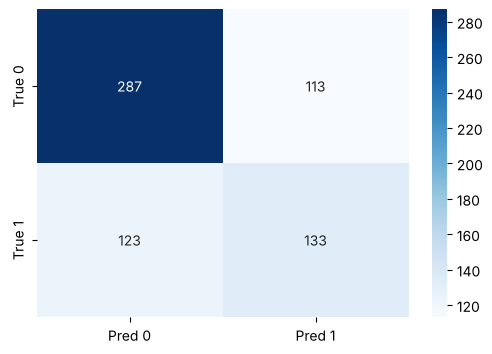

In [49]:
xgb_model_smote = XGBClassifier(
    n_estimators=200,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric="logloss"
)
xgb_model_smote.fit(X_train_smote, y_train_smote)

y_pred_xgb_smote = xgb_model_smote.predict(X_test_scaled)

cm = confusion_matrix(y_test, y_pred_xgb_smote)

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["True 0", "True 1"]
)

In [50]:
import warnings
warnings.filterwarnings("ignore")

import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(trial):
    params = {
        "n_estimators": trial.suggest_int("n_estimators", 100, 400),
        "max_depth": trial.suggest_int("max_depth", 3, 10),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
        "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
        "gamma": trial.suggest_float("gamma", 0.0, 5.0),
        "random_state": 42,
        "eval_metric": "logloss"
    }

    model = XGBClassifier(**params)
    model.fit(X_train_smote, y_train_smote)

    y_pred = model.predict(X_test_scaled)
    return f1_score(y_test, y_pred, pos_label=1)

study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
study.optimize(objective, n_trials=30, show_progress_bar=False)

print("Best trial:")
print("F1 classe 1 =", study.best_value)
print("Best params:")
print(study.best_params)

best_params = study.best_params.copy()
best_params["random_state"] = 42
best_params["eval_metric"] = "logloss"

Best trial:
F1 classe 1 = 0.55893536121673
Best params:
{'n_estimators': 125, 'max_depth': 5, 'learning_rate': 0.021059357965267162, 'subsample': 0.8829526820217537, 'colsample_bytree': 0.7334194270846313, 'min_child_weight': 4, 'gamma': 4.313606380523892}


Accuracy : 0.6463414634146342

Confusion Matrix :
[[277 123]
 [109 147]]

Classification Report :
              precision    recall  f1-score   support

           0       0.72      0.69      0.70       400
           1       0.54      0.57      0.56       256

    accuracy                           0.65       656
   macro avg       0.63      0.63      0.63       656
weighted avg       0.65      0.65      0.65       656



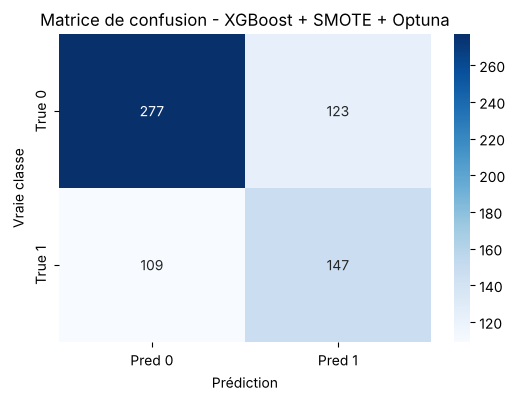

In [51]:
xgb_optuna = XGBClassifier(**best_params)
xgb_optuna.fit(X_train_smote, y_train_smote)

y_pred_xgb_optuna = xgb_optuna.predict(X_test_scaled)

print("Accuracy :", accuracy_score(y_test, y_pred_xgb_optuna))
print()
print("Confusion Matrix :")
cm = confusion_matrix(y_test, y_pred_xgb_optuna)
print(cm)
print()
print("Classification Report :")
print(classification_report(y_test, y_pred_xgb_optuna))

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred 0", "Pred 1"],
    yticklabels=["True 0", "True 1"]
)
plt.title("Matrice de confusion - XGBoost + SMOTE + Optuna")
plt.xlabel("Prédiction")
plt.ylabel("Vraie classe")
plt.show()


In [52]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# On crée un dictionnaire avec le nom souhaité et la variable de prédiction correspondante
# Assurez-vous que ces variables (y_pred_...) existent dans vos cellules précédentes
model_predictions = {
    "LogReg_balanced": y_pred_log,
    "LogReg_SMOTE": y_pred_log_smote,
    "KNN_SMOTE": y_pred_knn,
    "RandomForest": y_pred_rf,
    "RF_SMOTE": y_pred_rf_smote,
    "XGB_SMOTE": y_pred_xgb_smote,
    "XGB_Optuna": y_pred_xgb_optuna
}

# Extraction automatique
final_results = []

for name, y_pred in model_predictions.items():
    final_results.append({
        "Modele": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_classe_1": precision_score(y_test, y_pred, pos_label=1),
        "Recall_classe_1": recall_score(y_test, y_pred, pos_label=1),
        "F1_classe_1": f1_score(y_test, y_pred, pos_label=1)
    })

# Création et tri du DataFrame
comparison_final_df = pd.DataFrame(final_results)
comparison_final_df = comparison_final_df.sort_values(by="F1_classe_1", ascending=False).reset_index(drop=True)

# Affichage propre
print("--- Comparaison finale extraite du programme ---")
display(comparison_final_df.style.background_gradient(cmap='Blues', subset=['F1_classe_1', 'Accuracy']))

--- Comparaison finale extraite du programme ---


,Modele,Accuracy,Precision_classe_1,Recall_classe_1,F1_classe_1
0,XGB_Optuna,0.646341,0.544444,0.574219,0.558935
1,XGB_SMOTE,0.640244,0.540650,0.519531,0.529880
2,RF_SMOTE,0.653963,0.572139,0.449219,0.503282
3,RandomForest,0.649390,0.568421,0.421875,0.484305
4,KNN_SMOTE,0.583841,0.468635,0.496094,0.481973
5,LogReg_balanced,0.527439,0.418182,0.539062,0.470990
6,LogReg_SMOTE,0.525915,0.416413,0.535156,0.468376


In [53]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Comparaison finale avec calculs dynamiques
comparison_final = pd.DataFrame({
    "Modele": ["RF_SMOTE", "XGB_SMOTE", "XGB_Optuna"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_rf_smote),
        accuracy_score(y_test, y_pred_xgb_smote), 
        accuracy_score(y_test, y_pred_xgb_optuna)
    ],
    "Precision_classe_1": [
        precision_score(y_test, y_pred_rf_smote, pos_label=1),
        precision_score(y_test, y_pred_xgb_smote, pos_label=1),
        precision_score(y_test, y_pred_xgb_optuna, pos_label=1)
    ],
    "Recall_classe_1": [
        recall_score(y_test, y_pred_rf_smote, pos_label=1),
        recall_score(y_test, y_pred_xgb_smote, pos_label=1),
        recall_score(y_test, y_pred_xgb_optuna, pos_label=1)
    ],
    "F1_classe_1": [
        f1_score(y_test, y_pred_rf_smote, pos_label=1),
        f1_score(y_test, y_pred_xgb_smote, pos_label=1),
        f1_score(y_test, y_pred_xgb_optuna, pos_label=1)
    ]
})

print("\nComparaison finale :")
print(comparison_final.sort_values(by="F1_classe_1", ascending=False))


Comparaison finale :
       Modele  Accuracy  Precision_classe_1  Recall_classe_1  F1_classe_1
2  XGB_Optuna  0.646341            0.544444         0.574219     0.558935
1   XGB_SMOTE  0.640244            0.540650         0.519531     0.529880
0    RF_SMOTE  0.653963            0.572139         0.449219     0.503282


In [54]:
#
#
#
#
#
#
#
# SHAP
# On va expliquer le meilleur modèle final : xgb_optuna

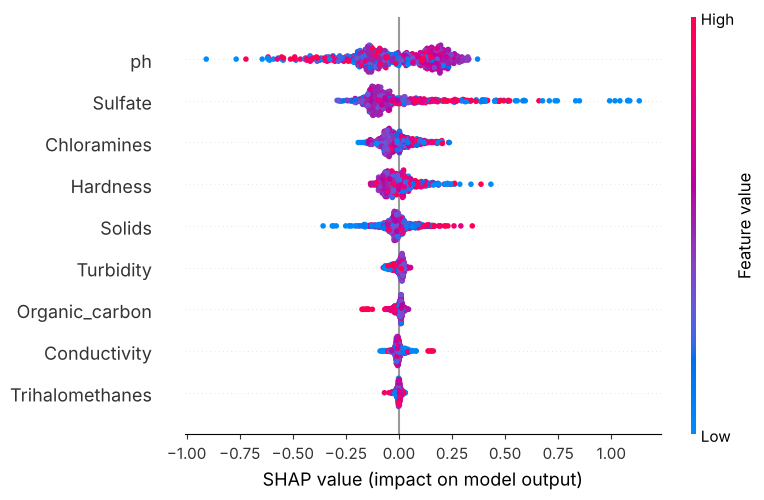

In [55]:
# Importance globale des variables

X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

explainer = shap.TreeExplainer(xgb_optuna)
shap_values = explainer.shap_values(X_test_scaled_df)

# Colonnes à afficher (aucune colonne type_vin dans ce dataset)
cols_to_keep = [col for col in X_test_scaled_df.columns if col != "type_vin"]
idx_to_keep = [i for i, col in enumerate(X_test_scaled_df.columns) if col != "type_vin"]

X_shap_plot = X_test_scaled_df[cols_to_keep]
shap_values_plot = shap_values[:, idx_to_keep]

shap.summary_plot(shap_values_plot, X_shap_plot)

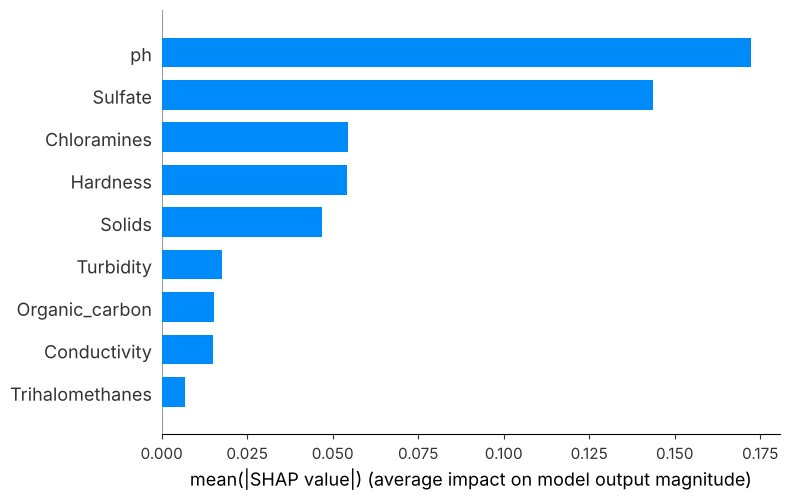

In [56]:
shap.summary_plot(shap_values_plot, X_shap_plot, plot_type="bar")

In [57]:
# Importance moyenne absolue des variables dans un tableau


shap_importance = pd.DataFrame({
    "feature": X.columns,
    "mean_abs_shap": np.abs(shap_values).mean(axis=0)
}).sort_values(by="mean_abs_shap", ascending=False)

print(shap_importance)

           feature  mean_abs_shap
0               ph       0.172166
4          Sulfate       0.143572
3      Chloramines       0.054559
1         Hardness       0.054211
2           Solids       0.046933
8        Turbidity       0.017650
6   Organic_carbon       0.015386
5     Conductivity       0.015098
7  Trihalomethanes       0.006774


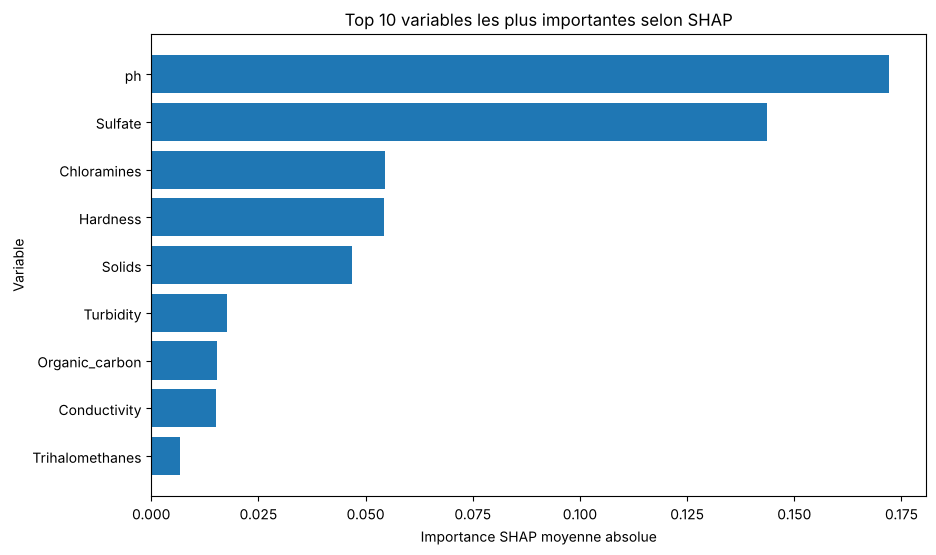

In [58]:
# Graphe des 10 variables les plus importantes

plt.figure(figsize=(10, 6))
top10 = shap_importance.head(10)

plt.barh(top10["feature"][::-1], top10["mean_abs_shap"][::-1])
plt.title("Top 10 variables les plus importantes selon SHAP")
plt.xlabel("Importance SHAP moyenne absolue")
plt.ylabel("Variable")
plt.show()

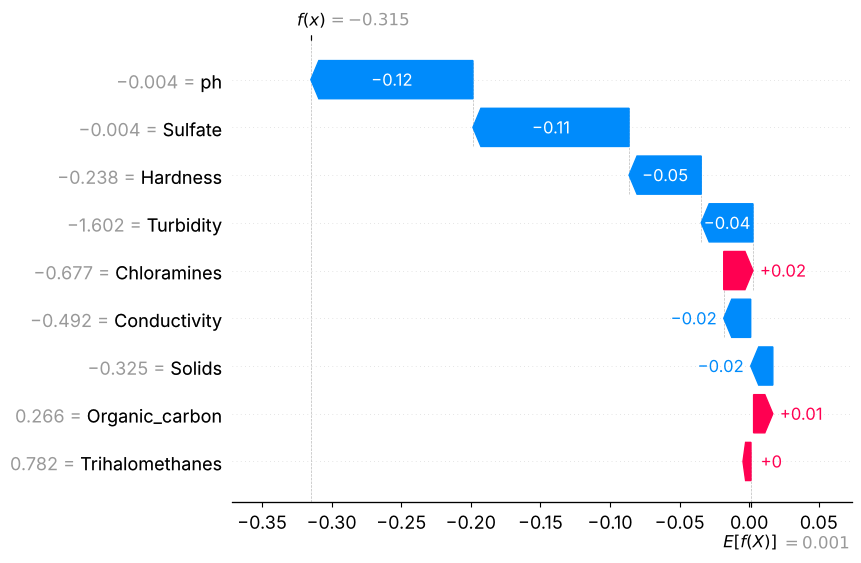

In [59]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_plot[0],
        base_values=explainer.expected_value,
        data=X_shap_plot.iloc[0],
        feature_names=X_shap_plot.columns.tolist()
    ),
    max_display=10
)

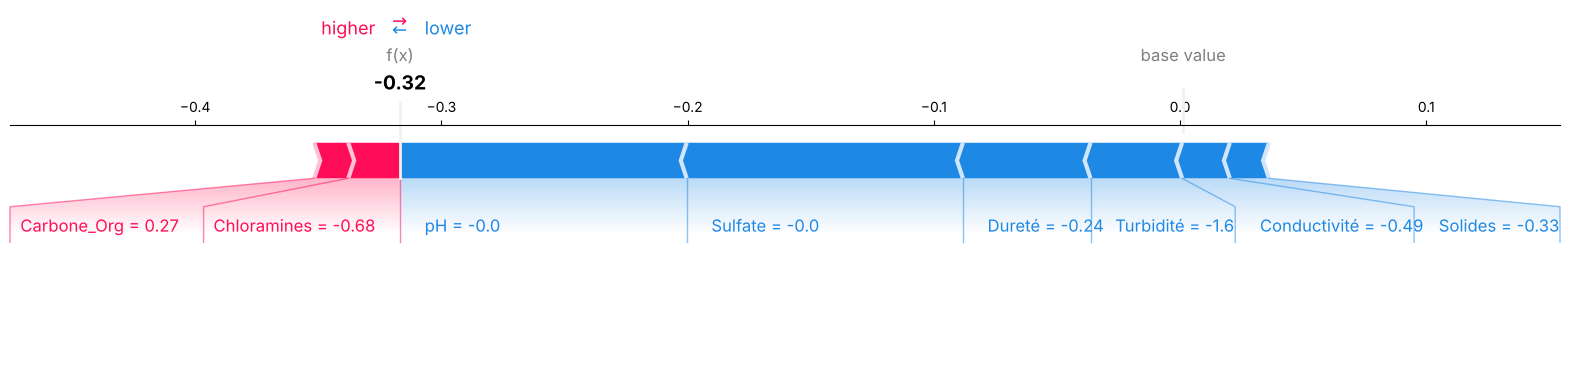

In [60]:
import numpy as np
import shap
import matplotlib.pyplot as plt

sample_idx = 0
top_k = 8

# On récupère les valeurs SHAP pour l'échantillon choisi
vals = shap_values_plot[sample_idx]
x_row = X_shap_plot.iloc[sample_idx].copy().round(2)

# Mise à jour du dictionnaire pour correspondre à VOTRE dataset (Parfum/Eau)
rename_map = {
    "ph": "pH",
    "Hardness": "Dureté",
    "Solids": "Solides",
    "Chloramines": "Chloramines",
    "Sulfate": "Sulfate",
    "Conductivity": "Conductivité",
    "Organic_carbon": "Carbone_Org",
    "Trihalomethanes": "Trihalométh",
    "Turbidity": "Turbidité"
}

# Application du renommage
x_row.index = [rename_map.get(c, c) for c in x_row.index]

# Sélection des top features qui influencent le plus la prédiction
top_idx = np.argsort(np.abs(vals))[-top_k:]
vals_top = vals[top_idx]
x_row_top = x_row.iloc[top_idx]

# Affichage du Force Plot
# Ce graphique explique pourquoi le modèle a prédit 0 ou 1 pour cet échantillon précis
shap.force_plot(
    explainer.expected_value,
    vals_top,
    x_row_top,
    matplotlib=True
)

plt.show()

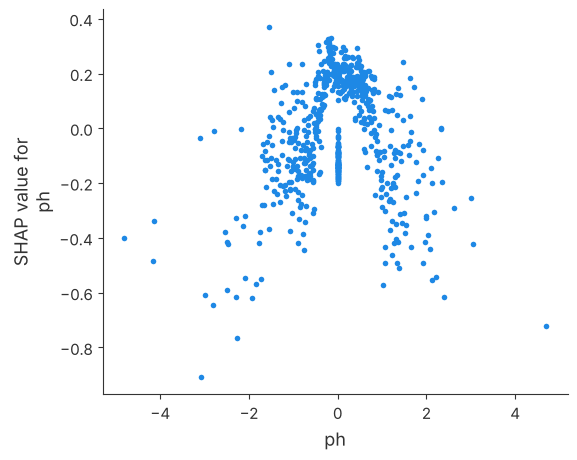

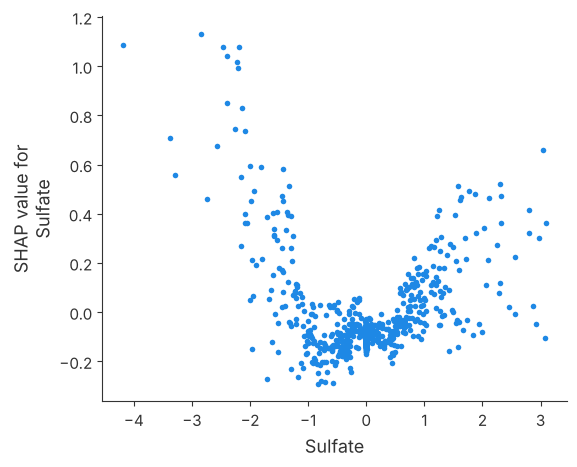

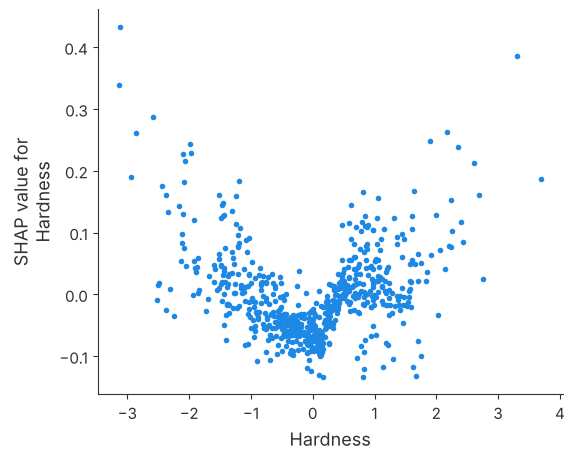

In [61]:
# On remplace par les colonnes de votre dataset actuel
# (ex: ph, Sulfate, Hardness sont souvent les plus importantes)
top_features = ["ph", "Sulfate", "Hardness"]

for feature in top_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_test_scaled_df, # Assurez-vous que c'est bien le nom de votre DataFrame de test avec colonnes
        interaction_index=None
    )

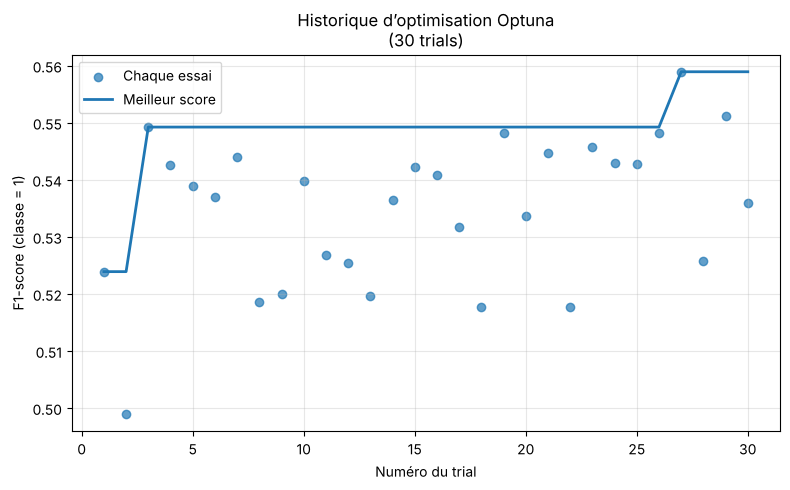

In [62]:
import matplotlib.pyplot as plt
import numpy as np

# Récupération des scores de chaque essai
scores = [trial.value for trial in study.trials]

# Meilleur score cumulé
best_scores = np.maximum.accumulate(scores)

# Numéros des essais
trials_number = np.arange(1, len(scores) + 1)

# Graphe
plt.figure(figsize=(8, 5))
plt.scatter(trials_number, scores, label="Chaque essai", alpha=0.7)
plt.plot(trials_number, best_scores, label="Meilleur score", linewidth=2)

plt.title("Historique d’optimisation Optuna\n(30 trials)")
plt.xlabel("Numéro du trial")
plt.ylabel("F1-score (classe = 1)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

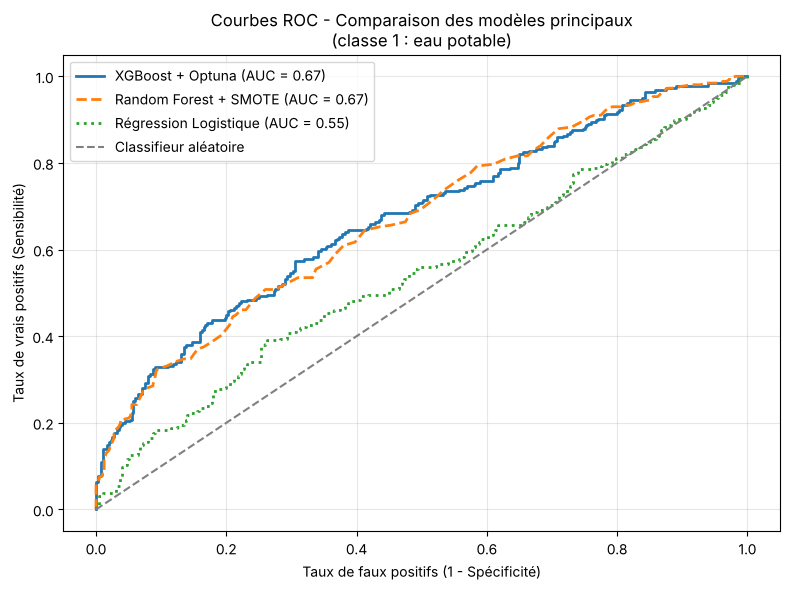

In [63]:
from sklearn.metrics import roc_curve, roc_auc_score

y_prob_xgb = xgb_optuna.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_model_smote.predict_proba(X_test_scaled)[:, 1]
y_prob_log = log_model_smote.predict_proba(X_test_scaled)[:, 1]

# Courbes ROC
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)

# AUC
auc_xgb = roc_auc_score(y_test, y_prob_xgb)
auc_rf = roc_auc_score(y_test, y_prob_rf)
auc_log = roc_auc_score(y_test, y_prob_log)

# Graphe
plt.figure(figsize=(8, 6))

plt.plot(fpr_xgb, tpr_xgb, linewidth=2,
         label=f"XGBoost + Optuna (AUC = {auc_xgb:.2f})")
plt.plot(fpr_rf, tpr_rf, linestyle="--", linewidth=2,
         label=f"Random Forest + SMOTE (AUC = {auc_rf:.2f})")
plt.plot(fpr_log, tpr_log, linestyle=":", linewidth=2,
         label=f"Régression Logistique (AUC = {auc_log:.2f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Classifieur aléatoire")

plt.title("Courbes ROC - Comparaison des modèles principaux\n(classe 1 : eau potable)")
plt.xlabel("Taux de faux positifs (1 - Spécificité)")
plt.ylabel("Taux de vrais positifs (Sensibilité)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

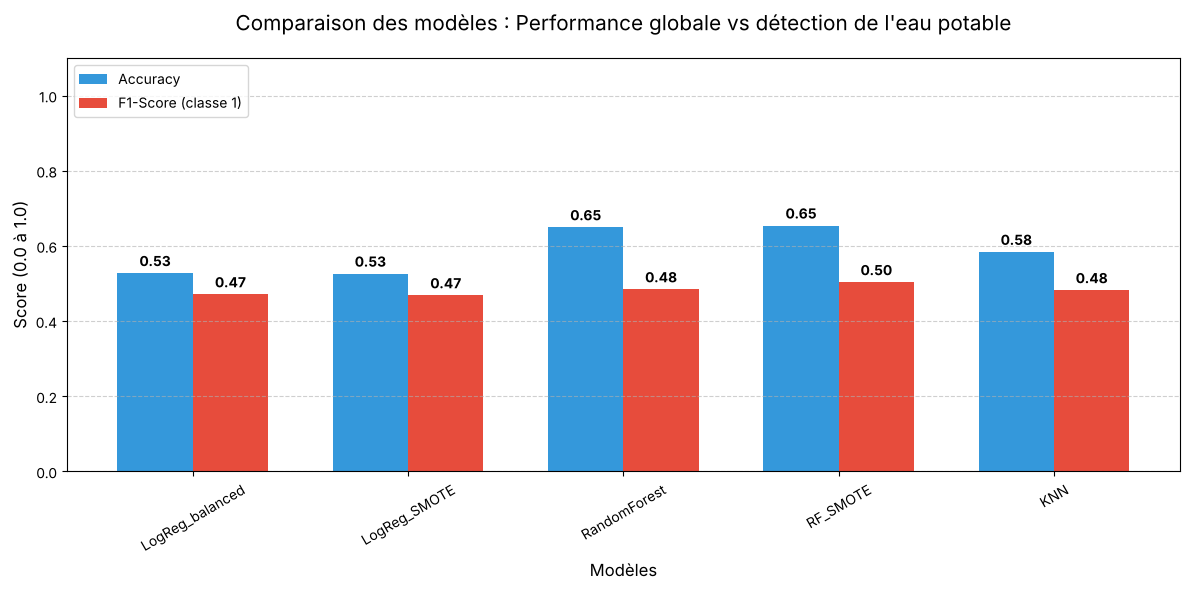

In [64]:
import matplotlib.pyplot as plt
import numpy as np

# Préparation des données à partir de votre DataFrame de comparaison
modeles = comparison_models["Modele"]
accuracy = comparison_models["Accuracy"]
f1_scores = comparison_models["F1_classe_1"]

# Configuration de la position des barres
x = np.arange(len(modeles))
width = 0.35 # Largeur des barres

# Création du graphique
plt.figure(figsize=(12, 6))
bars1 = plt.bar(x - width/2, accuracy, width, label="Accuracy", color='#3498db')
bars2 = plt.bar(x + width/2, f1_scores, width, label="F1-Score (classe 1)", color='#e74c3c')

# Fonction pour ajouter les étiquettes de score au-dessus de chaque barre
def add_labels(bars):
    for bar in bars:
        yval = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f"{yval:.2f}", 
                 ha='center', va='bottom', fontsize=10, fontweight='bold')

add_labels(bars1)
add_labels(bars2)

# Personnalisation des axes et du titre
plt.title("Comparaison des modèles : Performance globale vs détection de l'eau potable", size=15, pad=20)
plt.xlabel("Modèles", size=12)
plt.ylabel("Score (0.0 à 1.0)", size=12)
plt.xticks(x, modeles, rotation=30)
plt.ylim(0, 1.1) # On laisse un peu d'espace en haut pour les chiffres
plt.legend(loc="upper left")
plt.grid(axis="y", linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

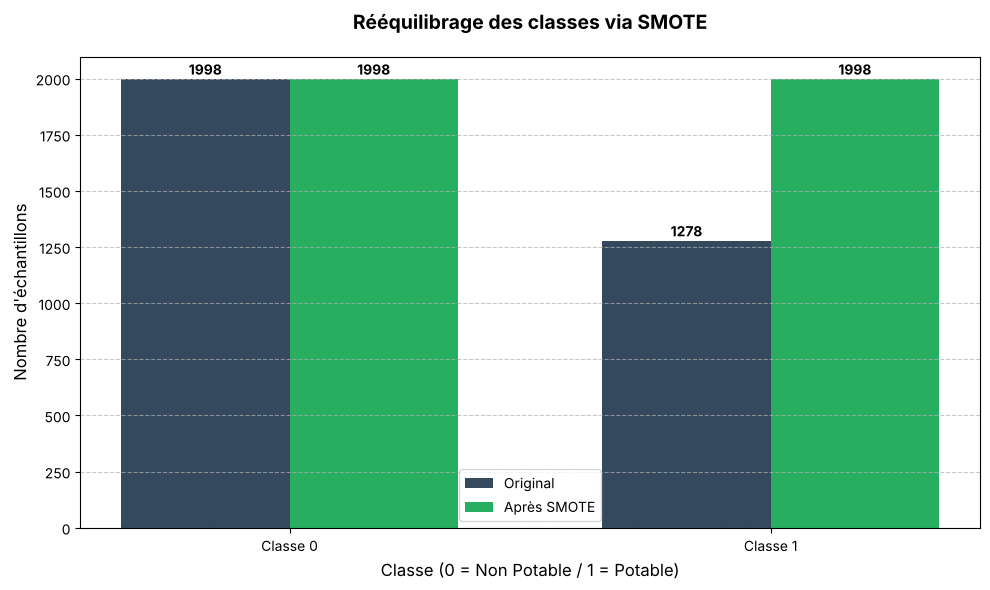

Ancien équilibre : {0: 1998, 1: 1278}
Nouvel équilibre : {0: 1998, 1: 1998}


In [65]:
from imblearn.over_sampling import SMOTE
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# -------------------------
# 1) Préparation des données
# -------------------------
# On suppose que 'df' est votre DataFrame principal
X = df.drop(columns=["Potability"]) # ou "good_quality" selon votre fichier
y = df["Potability"]

# Comptage avant SMOTE
counts_before = y.value_counts().sort_index()

# -------------------------
# 2) Appliquer SMOTE
# -------------------------
# SMOTE va créer des exemples synthétiques pour que la classe 0 et 1 soient égales
smote = SMOTE(random_state=42)
X_smote, y_smote = smote.fit_resample(X, y)

# Comptage après SMOTE
counts_after = pd.Series(y_smote).value_counts().sort_index()

# -------------------------
# 3) Tracé du graphique
# -------------------------
plt.figure(figsize=(10, 6))
width = 0.35
classes = counts_before.index
x = np.arange(len(classes))

# Barres
bars1 = plt.bar(x - width/2, counts_before.values, width, label="Original", color='#34495e')
bars2 = plt.bar(x + width/2, counts_after.values, width, label="Après SMOTE", color='#27ae60')

# Étiquettes et mise en forme
plt.title("Rééquilibrage des classes via SMOTE", fontsize=14, fontweight="bold", pad=20)
plt.xlabel("Classe (0 = Non Potable / 1 = Potable)", fontsize=12)
plt.ylabel("Nombre d'échantillons", fontsize=12)
plt.xticks(x, ["Classe 0", "Classe 1"])
plt.legend()

# Ajouter les valeurs au-dessus des barres
def autolabel(bars):
    for bar in bars:
        height = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2., height + 5,
                f'{int(height)}', ha='center', va='bottom', fontweight='bold')

autolabel(bars1)
autolabel(bars2)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

print(f"Ancien équilibre : {counts_before.to_dict()}")
print(f"Nouvel équilibre : {counts_after.to_dict()}")

In [66]:
# - matrice de confusion en heatmap
# - tableau final des métriques
# - top variables SHAP
# - résumé automatique prêt pour le rapport

# Prédictions finales du meilleur modèle
y_pred_final = y_pred_xgb_optuna

# Métriques finales
acc = accuracy_score(y_test, y_pred_final)
prec = precision_score(y_test, y_pred_final, pos_label=1)
rec = recall_score(y_test, y_pred_final, pos_label=1)
f1 = f1_score(y_test, y_pred_final, pos_label=1)
cm = confusion_matrix(y_test, y_pred_final)

final_metrics = pd.DataFrame({
    "Metric": ["Accuracy", "Precision_classe_1", "Recall_classe_1", "F1_classe_1"],
    "Value": [acc, prec, rec, f1]
})

print("=== Classification Report ===")
print(classification_report(y_test, y_pred_final))
print("\n=== Final Metrics ===")
print(final_metrics)

=== Classification Report ===
              precision    recall  f1-score   support

           0       0.72      0.69      0.70       400
           1       0.54      0.57      0.56       256

    accuracy                           0.65       656
   macro avg       0.63      0.63      0.63       656
weighted avg       0.65      0.65      0.65       656


=== Final Metrics ===
               Metric     Value
0            Accuracy  0.646341
1  Precision_classe_1  0.544444
2     Recall_classe_1  0.574219
3         F1_classe_1  0.558935


In [67]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

# Liste des modèles et de leurs prédictions respectives
# Assure-toi que ces variables existent dans ton notebook
model_data = [
    ("LogReg_balanced", y_pred_log),
    ("LogReg_SMOTE", y_pred_log_smote),
    ("KNN_SMOTE", y_pred_knn),
    ("RandomForest", y_pred_rf),
    ("RF_SMOTE", y_pred_rf_smote),
    ("XGB_SMOTE", y_pred_xgb_smote),
    ("XGB_Optuna", y_pred_xgb_optuna)
]

# Extraction dynamique des métriques
results = []
for name, y_pred in model_data:
    results.append({
        "Modele": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision_classe_1": precision_score(y_test, y_pred, pos_label=1),
        "Recall_classe_1": recall_score(y_test, y_pred, pos_label=1),
        "F1_classe_1": f1_score(y_test, y_pred, pos_label=1)
    })

# Création du DataFrame final
comparison_models = pd.DataFrame(results)

# Tri par F1-Score pour identifier le meilleur modèle
comparison_models = comparison_models.sort_values(by="F1_classe_1", ascending=False).reset_index(drop=True)

# Affichage du tableau formaté
print("--- Tableau de Comparaison Dynamique ---")
display(comparison_models.style.highlight_max(axis=0, color='lightgreen', subset=["Accuracy", "F1_classe_1"]))

--- Tableau de Comparaison Dynamique ---


,Modele,Accuracy,Precision_classe_1,Recall_classe_1,F1_classe_1
0,XGB_Optuna,0.646341,0.544444,0.574219,0.558935
1,XGB_SMOTE,0.640244,0.540650,0.519531,0.529880
2,RF_SMOTE,0.653963,0.572139,0.449219,0.503282
3,RandomForest,0.649390,0.568421,0.421875,0.484305
4,KNN_SMOTE,0.583841,0.468635,0.496094,0.481973
5,LogReg_balanced,0.527439,0.418182,0.539062,0.470990
6,LogReg_SMOTE,0.525915,0.416413,0.535156,0.468376


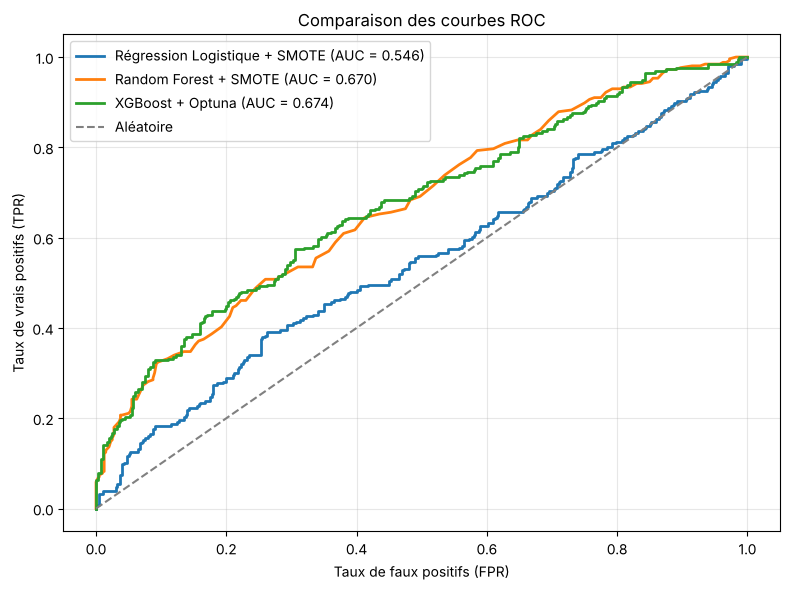

===== Tableau récapitulatif =====
                          Modèle  Accuracy  Precision    Recall  F1-score  \
2               XGBoost + Optuna  0.646341   0.544444  0.574219  0.558935   
1          Random Forest + SMOTE  0.653963   0.572139  0.449219  0.503282   
0  Régression Logistique + SMOTE  0.525915   0.416413  0.535156  0.468376   

    AUC ROC  
2  0.674072  
1  0.669824  
0  0.545684  

===== Matrices de confusion =====

Régression Logistique + SMOTE
[[208 192]
 [119 137]]

Random Forest + SMOTE
[[314  86]
 [141 115]]

XGBoost + Optuna
[[277 123]
 [109 147]]

===== Classification report =====

Régression Logistique + SMOTE
              precision    recall  f1-score   support

           0       0.64      0.52      0.57       400
           1       0.42      0.54      0.47       256

    accuracy                           0.53       656
   macro avg       0.53      0.53      0.52       656
weighted avg       0.55      0.53      0.53       656


Random Forest + SMOTE
         

In [68]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

# =========================================================
# 1) Liste des modèles à comparer
# =========================================================
models = {
    "Régression Logistique + SMOTE": log_model_smote,
    "Random Forest + SMOTE": rf_model_smote,
    "XGBoost + Optuna": xgb_optuna
}

# =========================================================
# 2) Évaluation
# =========================================================
results = []
conf_matrices = {}

plt.figure(figsize=(8, 6))

for name, model in models.items():
    
    # Prédictions de classes
    y_pred = model.predict(X_test_scaled)
    
    # Probabilités pour la classe 1
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Métriques
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    auc = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred)
    
    # Stockage
    results.append({
        "Modèle": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1,
        "AUC ROC": auc
    })
    
    conf_matrices[name] = cm
    
    # Courbe ROC
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")

# Ligne aléatoire
plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Aléatoire")

plt.title("Comparaison des courbes ROC")
plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# =========================================================
# 3) Tableau récapitulatif
# =========================================================
results_df = pd.DataFrame(results).sort_values(by="AUC ROC", ascending=False)

print("===== Tableau récapitulatif =====")
print(results_df)

# =========================================================
# 4) Matrices de confusion
# =========================================================
print("\n===== Matrices de confusion =====")
for name, cm in conf_matrices.items():
    print(f"\n{name}")
    print(cm)

# =========================================================
# 5) Classification report détaillé
# =========================================================
print("\n===== Classification report =====")
for name, model in models.items():
    y_pred = model.predict(X_test_scaled)
    print(f"\n{name}")
    print(classification_report(y_test, y_pred, zero_division=0))